## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Andrés Felipe Vargas Gómez" # @param {"type":"string"}
carnet = 10001142 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa tiene varias tareas técnicas que debe atender.  Algunas son más urgentes que otras, necesitamos organizar las tareas que se deben de atender para procesar primero la que tenga la prioridad más alta.

También se tienen seis dispositivos ubicados en diferentes posiciones. Se quiere conectarlos usando la menor cantidad total de cable posible, sin dejar dispositivos desconectados.

Para resolverlo se usa un Max-Heap para las tareas y el algoritmo de Kruskal para encontrar el árbol de expansión mínima.


## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.


Requerimientos funcionales:


1) Guardar las tareas con su código, descripción y prioridad.


2) Construir un Max-Heap a partir de las tareas.


3) Extraer las dos tareas con mayor prioridad.


4) Mostrar los seis dispositivos en un plano.


5) Calcular la distancia entre cada pareja de dispositivos.





Requerimientos no funcionales:


1) Las operaciones del Max-Heap deben programarse manualmente.


2) No se debe utilizar heapq.


3) Kruskal debe estar implementado manualmente, sin una función de librería que calcule el MST.


4) Los resultados y las gráficas deben poder verse en el Notebook.


5) El código debe estar dividido en partes y tener nombres fáciles de entender.


## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.



Historia 1: Como encargado de las tareas, quiero organizarlas por prioridad para atender primero la más importante.
Criterios de aceptación: el programa construye el Max-Heap y muestra el arreglo y su representación.

Historia 2: Como encargado, quiero procesar las dos tareas más urgentes para saber cuáles se atienden primero.
Criterios de aceptación: se extraen dos tareas y se muestra el Heap después de cada extracción.


Historia 3: Como encargado de los dispositivos, quiero conocer las distancias entre ellos para comparar las conexiones posibles.
Criterios de aceptación: se muestran los seis dispositivos y se calculan las 15 distancias.

Historia 4: Como encargado, quiero conectar todos los dispositivos con el menor cable posible.
Criterios de aceptación: Kruskal selecciona cinco conexiones, no forma ciclos y calcula la longitud total.

## 4) Diagramas de flujo **[5 pts]**
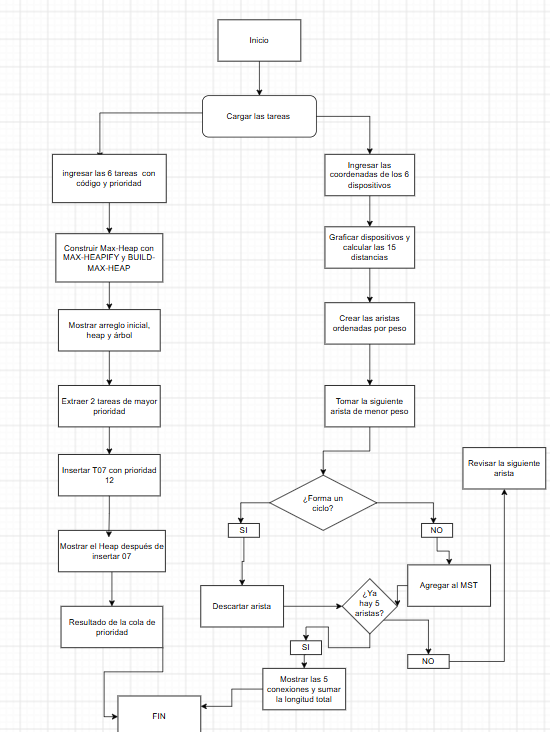

Descripción:

El diagrama de flujo muestra el proceso que realiza el algoritmo primero construye el Max-Heap  y se procesan las tareas según su prioridad. Despúes, se calculan las distancias entre los dispositivos y se aplica el algoritmo de Kruskal para seleccionar las conexiones de menor costo sin formar ciclos, hasta obtener el árbol de expansión mínima.


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación:

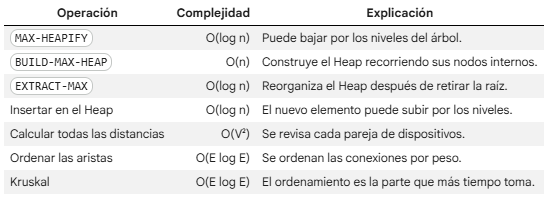


Funciones T[n]
Para las operaciones principales del Heap se puede expresar el trabajo así:

MAX-HEAPIFY: T(n) = c · log₂(n), porque baja como máximo por la altura del árbol.


EXTRACT-MAX: T(n) = c₁ + c₂ · log₂(n), porque retira la raíz y luego reorganiza el Heap.


BUILD-MAX-HEAP: T(n) = O(n), porque no todos los nodos necesitan bajar hasta las hojas.


Para Kruskal, el ordenamiento de las E aristas domina el tiempo: T(E) = O(E log E)
- Función T[n]:

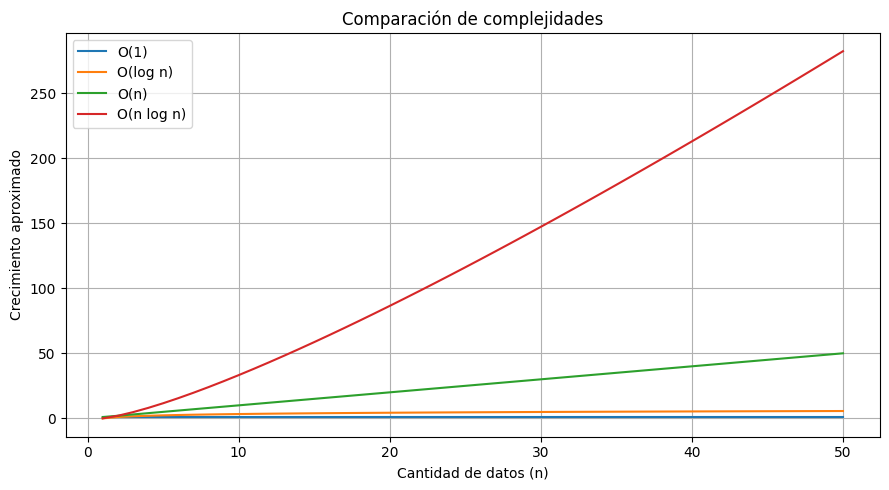





## 6. Código funcional

### Punto 1. Construcción del Max-Heap

Se guarda cada tarea como una lista con su código, nombre y prioridad. Para comparar las tareas se utiliza el valor de prioridad, que está en la posición 2.

In [7]:
tareas = [
    ["T01", "Configurar servidor", 6],
    ["T02", "Reparar sensor", 10],
    ["T03", "Actualizar software", 4],
    ["T04", "Revisar cámara", 8],
    ["T05", "Generar respaldo", 3],
    ["T06", "Configurar alarma", 7]
]

print("Arreglo inicial:")
for tarea in tareas:
    print(tarea)

Arreglo inicial:
['T01', 'Configurar servidor', 6]
['T02', 'Reparar sensor', 10]
['T03', 'Actualizar software', 4]
['T04', 'Revisar cámara', 8]
['T05', 'Generar respaldo', 3]
['T06', 'Configurar alarma', 7]


In [9]:
def max_heapify(heap, i, tamano):
    mayor = i
    izquierda = 2 * i + 1
    derecha = 2 * i + 2

    if izquierda < tamano and heap[izquierda][2] > heap[mayor][2]:
        mayor = izquierda

    if derecha < tamano and heap[derecha][2] > heap[mayor][2]:
        mayor = derecha

    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor, tamano)


def build_max_heap(heap):
    tamano = len(heap)
    for i in range(tamano // 2 - 1, -1, -1):
        max_heapify(heap, i, tamano)


heap = tareas.copy()
build_max_heap(heap)

print("Max-Heap resultante:")
for tarea in heap:
    print(tarea)

Max-Heap resultante:
['T02', 'Reparar sensor', 10]
['T04', 'Revisar cámara', 8]
['T06', 'Configurar alarma', 7]
['T01', 'Configurar servidor', 6]
['T05', 'Generar respaldo', 3]
['T03', 'Actualizar software', 4]


In [10]:
def mostrar_heap(heap):
    if len(heap) == 0:
        print("El Heap está vacío")
        return

    nivel = 0
    inicio = 0
    while inicio < len(heap):
        cantidad = 2 ** nivel
        fin = min(inicio + cantidad, len(heap))
        valores = [f"{heap[i][0]} ({heap[i][2]})" for i in range(inicio, fin)]
        print("Nivel", nivel, ":", "   ".join(valores))
        inicio = fin
        nivel += 1

print("Árbol del Max-Heap:")
mostrar_heap(heap)

Árbol del Max-Heap:
Nivel 0 : T02 (10)
Nivel 1 : T04 (8)   T06 (7)
Nivel 2 : T01 (6)   T05 (3)   T03 (4)


### Punto 2. Procesamiento de tareas

`EXTRACT-MAX` retira la tarea que está en la raíz, porque es la que tiene mayor prioridad. Después se coloca el último elemento en la raíz y se reorganiza el Heap.

In [12]:
def extract_max(heap):
    if len(heap) == 0:
        return None

    mayor = heap[0]
    ultimo = heap.pop()

    if len(heap) > 0:
        heap[0] = ultimo
        max_heapify(heap, 0, len(heap))

    return mayor


print("Primera tarea procesada:")
print(extract_max(heap))
print("Heap después de la primera extracción:")
mostrar_heap(heap)

print("\nSegunda tarea procesada:")
print(extract_max(heap))
print("Heap después de la segunda extracción:")
mostrar_heap(heap)

Primera tarea procesada:
['T06', 'Configurar alarma', 7]
Heap después de la primera extracción:
Nivel 0 : T01 (6)
Nivel 1 : T03 (4)   T05 (3)

Segunda tarea procesada:
['T01', 'Configurar servidor', 6]
Heap después de la segunda extracción:
Nivel 0 : T03 (4)
Nivel 1 : T05 (3)


In [13]:
def insertar(heap, tarea):
    heap.append(tarea)
    i = len(heap) - 1

    while i > 0:
        padre = (i - 1) // 2

        if heap[i][2] > heap[padre][2]:
            heap[i], heap[padre] = heap[padre], heap[i]
            i = padre
        else:
            break


nueva_tarea = ["T07", "Falla en sistema contra incendios", 12]
insertar(heap, nueva_tarea)

print("Heap después de insertar T07:")
mostrar_heap(heap)

Heap después de insertar T07:
Nivel 0 : T07 (12)
Nivel 1 : T05 (3)   T03 (4)


### Punto 3. Dispositivos y cálculo de distancias

Se guardan las coordenadas de cada dispositivo. Después se recorren las parejas sin repetir conexiones y se calcula su distancia con la fórmula del enunciado.

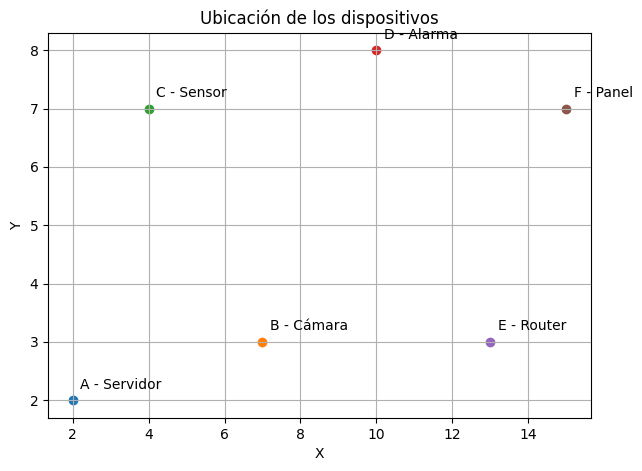

In [14]:
import math
import itertools
import matplotlib.pyplot as plt

dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Cámara", 7, 3),
    "C": ("Sensor", 4, 7),
    "D": ("Alarma", 10, 8),
    "E": ("Router", 13, 3),
    "F": ("Panel", 15, 7)
}

plt.figure(figsize=(7, 5))
for id_dispositivo, datos in dispositivos.items():
    nombre, x, y = datos
    plt.scatter(x, y)
    plt.text(x + 0.2, y + 0.2, f"{id_dispositivo} - {nombre}")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Ubicación de los dispositivos")
plt.grid(True)
plt.show()

In [15]:
aristas = []

for id1, id2 in itertools.combinations(dispositivos.keys(), 2):
    x1, y1 = dispositivos[id1][1], dispositivos[id1][2]
    x2, y2 = dispositivos[id2][1], dispositivos[id2][2]

    distancia = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    aristas.append((distancia, id1, id2))

print("Distancias entre las parejas:")
for peso, origen, destino in aristas:
    print(f"{origen} - {destino}: {peso:.2f}")

print("\nCantidad de aristas:", len(aristas))

Distancias entre las parejas:
A - B: 5.10
A - C: 5.39
A - D: 10.00
A - E: 11.05
A - F: 13.93
B - C: 5.00
B - D: 5.83
B - E: 6.00
B - F: 8.94
C - D: 6.08
C - E: 9.85
C - F: 11.00
D - E: 5.83
D - F: 5.10
E - F: 4.47

Cantidad de aristas: 15


### Punto 4. Árbol de expansión mínima con Kruskal

Primero se ordenan las aristas por distancia. Para evitar ciclos se utiliza una lista de grupos: si los dos dispositivos ya están en el mismo grupo, esa conexión se descarta. Si están en grupos diferentes, se unen.

In [16]:
aristas_ordenadas = sorted(aristas)

print("Aristas ordenadas por peso:")
for peso, origen, destino in aristas_ordenadas:
    print(f"{origen} - {destino}: {peso:.2f}")

Aristas ordenadas por peso:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
A - C: 5.39
B - D: 5.83
D - E: 5.83
B - E: 6.00
C - D: 6.08
B - F: 8.94
C - E: 9.85
A - D: 10.00
C - F: 11.00
A - E: 11.05
A - F: 13.93


In [17]:
def buscar(grupos, dispositivo):
    for grupo in grupos:
        if dispositivo in grupo:
            return grupo
    return None


def kruskal(dispositivos, aristas):
    grupos = [{id_dispositivo} for id_dispositivo in dispositivos]
    mst = []

    for peso, origen, destino in sorted(aristas):
        grupo1 = buscar(grupos, origen)
        grupo2 = buscar(grupos, destino)

        if grupo1 != grupo2:
            mst.append((peso, origen, destino))
            grupo1.update(grupo2)
            grupos.remove(grupo2)

        if len(mst) == len(dispositivos) - 1:
            break

    return mst


mst = kruskal(dispositivos, aristas)

print("Conexiones seleccionadas:")
total = 0
for peso, origen, destino in mst:
    print(f"{origen} - {destino}: {peso:.2f}")
    total += peso

print(f"\nLongitud total de cable: {total:.2f}")

Conexiones seleccionadas:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
B - D: 5.83

Longitud total de cable: 25.50


### Punto 5. Gráfica final del MST

En esta gráfica se muestran los seis dispositivos y solamente las conexiones que seleccionó Kruskal. El peso de cada conexión aparece sobre la línea.

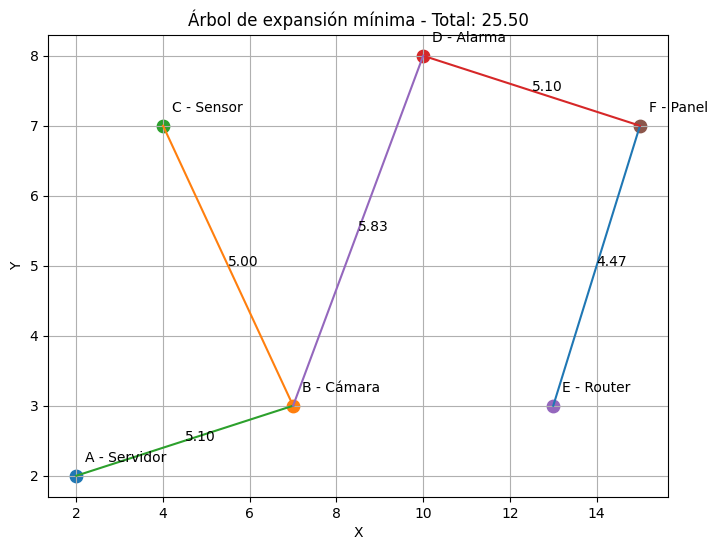

In [18]:
plt.figure(figsize=(8, 6))

for id_dispositivo, datos in dispositivos.items():
    nombre, x, y = datos
    plt.scatter(x, y, s=80)
    plt.text(x + 0.2, y + 0.2, f"{id_dispositivo} - {nombre}")

for peso, origen, destino in mst:
    x1, y1 = dispositivos[origen][1], dispositivos[origen][2]
    x2, y2 = dispositivos[destino][1], dispositivos[destino][2]

    plt.plot([x1, x2], [y1, y2])
    medio_x = (x1 + x2) / 2
    medio_y = (y1 + y2) / 2
    plt.text(medio_x, medio_y, f"{peso:.2f}")

plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Árbol de expansión mínima - Total: {total:.2f}")
plt.grid(True)
plt.show()

## 7) Tests aplicados **[15 pts]**

In [ ]:
# Función para comprobar que el Max-Heap esté organizado correctamente:
def heap_correcto(heap):
    for i in range(len(heap)):
        izquierda = 2 * i + 1
        derecha = 2 * i + 2

        if izquierda < len(heap):
            if heap[i][2] < heap[izquierda][2]:
                return False

        if derecha < len(heap):
            if heap[i][2] < heap[derecha][2]:
                return False

    return True


# PRUEBA 1: Construcción del Max-Heap
heap_prueba = [
    ["T01", "Configurar servidor", 6],
    ["T02", "Reparar sensor", 10],
    ["T03", "Actualizar software", 4],
    ["T04", "Revisar cámara", 8],
    ["T05", "Generar respaldo", 3],
    ["T06", "Configurar alarma", 7]
]

build_max_heap(heap_prueba)

assert heap_correcto(heap_prueba)
assert heap_prueba[0][2] == 10
print("Prueba 1 aprobada: construcción del Max-Heap.")


# PRUEBA 2: Extracción de la tarea con mayor prioridad:
primera = extract_max(heap_prueba)

assert primera[0] == "T02"
assert primera[2] == 10
assert heap_correcto(heap_prueba)
print("Prueba 2 aprobada: extracción de la prioridad más alta.")


# PRUEBA 3: Inserción de una nueva tarea:
insertar(heap_prueba, ["T07", "Falla en sistema contra incendios", 12])

assert heap_prueba[0][0] == "T07"
assert heap_correcto(heap_prueba)
print("Prueba 3 aprobada: inserción de T07.")


# PRUEBA 4: Extracción de un Heap vacío:
heap_vacio = []

resultado = extract_max(heap_vacio)

assert resultado is None
assert len(heap_vacio) == 0
print("Prueba 4 aprobada: extracción de un Heap vacío.")


# PRUEBA 5: Cálculo de las distancias:
assert len(dispositivos) == 6
assert len(aristas) == 15

print("Prueba 5 aprobada: cálculo de las 15 distancias.")


# PRUEBA 6: Cantidad de conexiones del MST:
assert len(mst) == 5

print("Prueba 6 aprobada: el MST tiene cinco conexiones.")


# PRUEBA 7: Todos los dispositivos están conectados:
grafo_prueba = {d: [] for d in dispositivos}

for peso, origen, destino in mst:
    grafo_prueba[origen].append(destino)
    grafo_prueba[destino].append(origen)

visitados = set()
pendientes = ["A"]

while pendientes:
    actual = pendientes.pop()

    if actual not in visitados:
        visitados.add(actual)

        for vecino in grafo_prueba[actual]:
            if vecino not in visitados:
                pendientes.append(vecino)

assert visitados == set(dispositivos.keys())

print("Prueba 7 aprobada: todos los dispositivos están conectados.")


# PRUEBA 8: Comprobar la longitud total del MST
total_prueba = sum(peso for peso, origen, destino in mst)

assert round(total_prueba, 2) == 25.50
assert round(total_prueba, 2) == round(total, 2)

print("Prueba 8 aprobada: longitud total del MST.")
print("Longitud comprobada:", round(total_prueba, 2))


print("\nTodas las pruebas fueron ejecutadas correctamente.")